# Influencia de la clase marquise con menos imágenes

In [1]:
import os
import shutil
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import classification_report

from particion_dataset import dividir_clase
from utilidades import crear_dataloaders, ejecutar_configuracion, evaluar, dibujar_matriz_confusion, device

print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


## Mejor configuración de la búsqueda manual

In [2]:
mejor_configuracion = {
    'tam_imagen': 128,
    'tam_lote': 64,
    'lr': 0.001,
    'filtros': (16, 32, 64),
    'neuronas_fc': (128,),
    'activacion': nn.ReLU,
    'p_dropout': 0.25,
}

## Creación del dataset con 8 clases

In [3]:
ruta_datos_marquise = 'datos_marquise'

if not os.path.exists(ruta_datos_marquise):
    shutil.copytree('datos', ruta_datos_marquise)
    dividir_clase('marquise', ruta_datos_marquise)

dataloader_entrenamiento, dataloader_validacion, dataloader_test, clases = crear_dataloaders(
    ruta_datos_marquise, mejor_configuracion['tam_imagen'], mejor_configuracion['tam_lote'])

recuento_entrenamiento = Counter(dataloader_entrenamiento.dataset.targets)
for indice, clase in enumerate(clases):
    print(f'{clase:9s} | training: {recuento_entrenamiento[indice]:4d}')

cushion   | training: 2373
emerald   | training: 2373
heart     | training: 2373
marquise  | training:  325
oval      | training: 2373
pear      | training: 2373
princess  | training: 2373
round     | training: 2373


## Entrenamiento con 8 clases

Época [ 1/40] | Train Loss: 0.2613 | Train Acc: 0.9468 | Val Loss: 0.0210 | Val Acc: 0.9948 *


Época [ 2/40] | Train Loss: 0.0396 | Train Acc: 0.9911 | Val Loss: 0.0185 | Val Acc: 0.9950 *


Época [ 3/40] | Train Loss: 0.0281 | Train Acc: 0.9932 | Val Loss: 0.0190 | Val Acc: 0.9970 


Época [ 4/40] | Train Loss: 0.0225 | Train Acc: 0.9948 | Val Loss: 0.0216 | Val Acc: 0.9972 


Época [ 5/40] | Train Loss: 0.0206 | Train Acc: 0.9952 | Val Loss: 0.0132 | Val Acc: 0.9970 *


...

Época [ 7/40] | Train Loss: 0.0130 | Train Acc: 0.9966 | Val Loss: 0.0200 | Val Acc: 0.9956 


Época [ 8/40] | Train Loss: 0.0146 | Train Acc: 0.9956 | Val Loss: 0.0181 | Val Acc: 0.9964 


Época [ 9/40] | Train Loss: 0.0227 | Train Acc: 0.9944 | Val Loss: 0.0182 | Val Acc: 0.9970 


Época [10/40] | Train Loss: 0.0130 | Train Acc: 0.9963 | Val Loss: 0.0163 | Val Acc: 0.9970 


Época [11/40] | Train Loss: 0.0078 | Train Acc: 0.9976 | Val Loss: 0.0157 | Val Acc: 0.9978 
Parada anticipada: 5 épocas sin mejorar la pérdida de validación
Mejor época: 6 | Tiempo total: 212.2 segundos


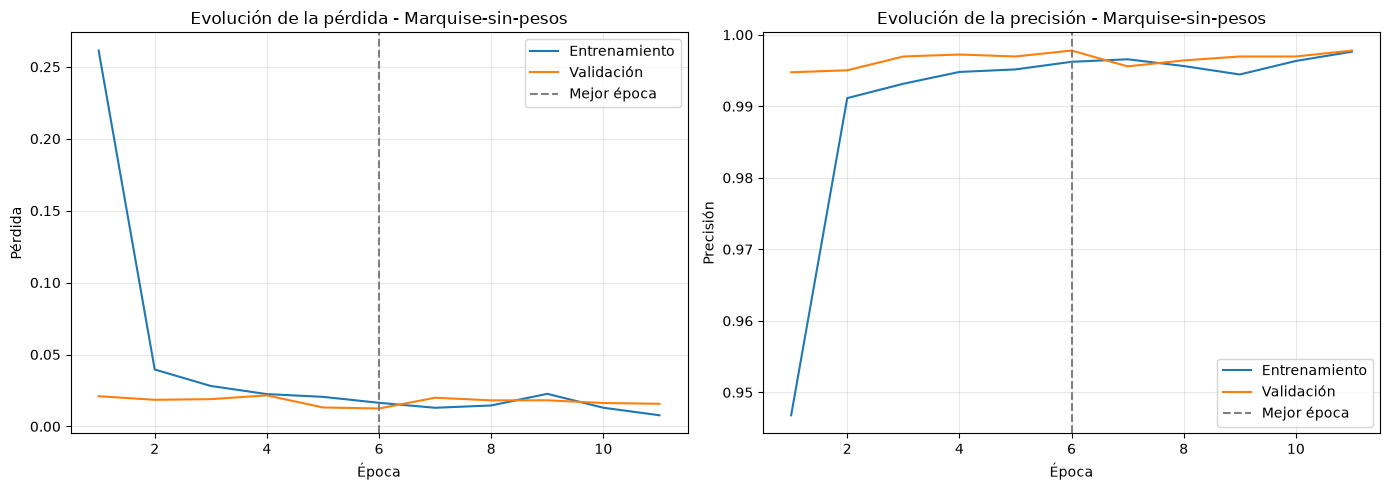

Test Acc: 0.9973
              precision    recall  f1-score   support

     cushion     0.9980    0.9980    0.9980       510
     emerald     0.9980    0.9961    0.9971       510
       heart     0.9980    0.9980    0.9980       510
    marquise     1.0000    0.9859    0.9929        71
        oval     0.9942    1.0000    0.9971       510
        pear     0.9941    0.9980    0.9961       510
    princess     1.0000    0.9922    0.9961       510
       round     0.9980    1.0000    0.9990       510

    accuracy                         0.9973      3641
   macro avg     0.9976    0.9960    0.9968      3641
weighted avg     0.9973    0.9973    0.9973      3641



In [4]:
modelo_sin_pesos, historial_sin_pesos = ejecutar_configuracion(
    'Marquise-sin-pesos', ruta_datos=ruta_datos_marquise, **mejor_configuracion)

y_real, y_pred_sin_pesos, _, acc_sin_pesos = evaluar(modelo_sin_pesos, dataloader_test)
print(f'Test Acc: {acc_sin_pesos:.4f}')
print(classification_report(y_real, y_pred_sin_pesos, target_names=clases, digits=4))

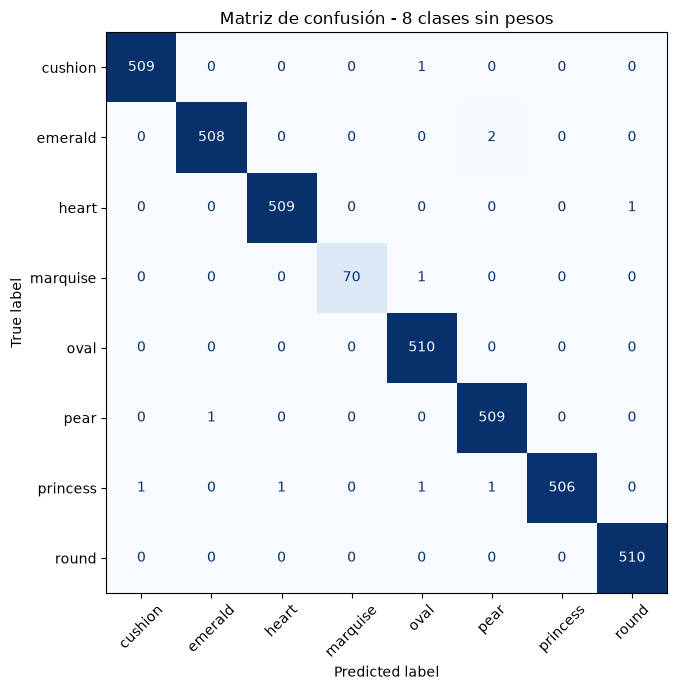

In [5]:
dibujar_matriz_confusion(y_real, y_pred_sin_pesos, clases, '8 clases sin pesos',
                         'graficas/matriz_marquise-sin-pesos.png')

## Entrenamiento con pesos por clase en la función de pérdida

In [6]:
num_imagenes = np.array([recuento_entrenamiento[indice] for indice in range(len(clases))])
pesos = num_imagenes.sum() / (len(clases) * num_imagenes)
criterio_ponderado = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32).to(device))

for clase, peso in zip(clases, pesos):
    print(f'{clase:9s} | peso: {peso:.3f}')

cushion   | peso: 0.892
emerald   | peso: 0.892
heart     | peso: 0.892
marquise  | peso: 6.514
oval      | peso: 0.892
pear      | peso: 0.892
princess  | peso: 0.892
round     | peso: 0.892


Época [ 1/40] | Train Loss: 0.2862 | Train Acc: 0.9404 | Val Loss: 0.0267 | Val Acc: 0.9948 *


Época [ 2/40] | Train Loss: 0.0543 | Train Acc: 0.9887 | Val Loss: 0.0284 | Val Acc: 0.9942 


Época [ 3/40] | Train Loss: 0.0348 | Train Acc: 0.9910 | Val Loss: 0.0266 | Val Acc: 0.9967 *


Época [ 4/40] | Train Loss: 0.0348 | Train Acc: 0.9909 | Val Loss: 0.0183 | Val Acc: 0.9964 *


Época [ 5/40] | Train Loss: 0.0413 | Train Acc: 0.9903 | Val Loss: 0.0232 | Val Acc: 0.9956 


...

Época [ 7/40] | Train Loss: 0.0176 | Train Acc: 0.9961 | Val Loss: 0.0163 | Val Acc: 0.9975 


Época [ 8/40] | Train Loss: 0.0229 | Train Acc: 0.9945 | Val Loss: 0.0197 | Val Acc: 0.9967 


Época [ 9/40] | Train Loss: 0.0158 | Train Acc: 0.9962 | Val Loss: 0.0207 | Val Acc: 0.9970 


Época [10/40] | Train Loss: 0.0103 | Train Acc: 0.9969 | Val Loss: 0.0226 | Val Acc: 0.9967 


Época [11/40] | Train Loss: 0.0118 | Train Acc: 0.9963 | Val Loss: 0.0268 | Val Acc: 0.9964 
Parada anticipada: 5 épocas sin mejorar la pérdida de validación
Mejor época: 6 | Tiempo total: 221.9 segundos


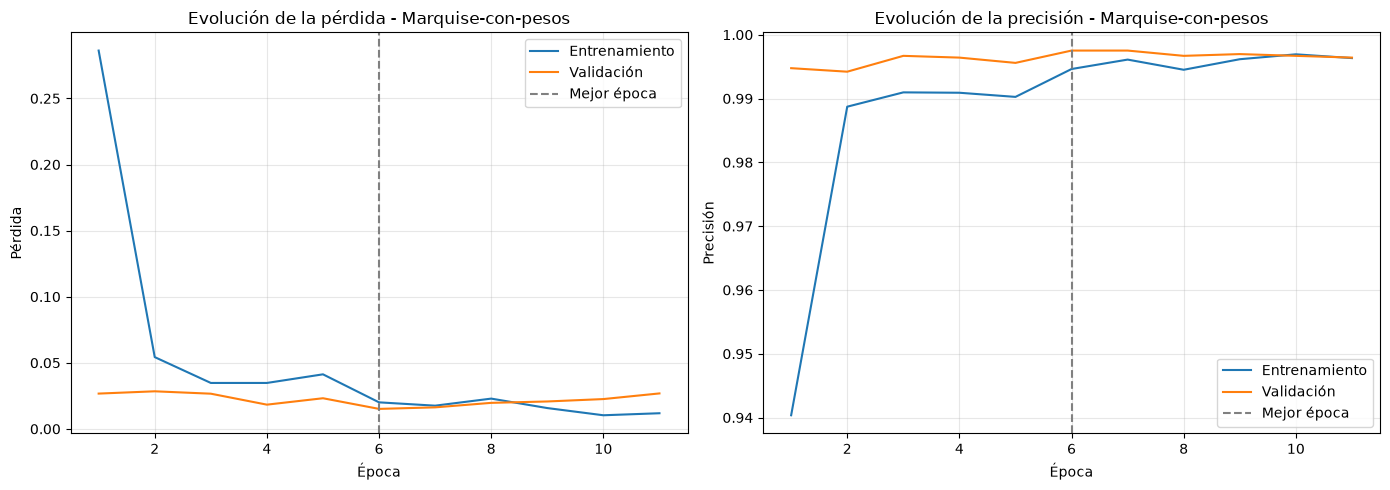

Test Acc: 0.9973
              precision    recall  f1-score   support

     cushion     0.9942    1.0000    0.9971       510
     emerald     0.9980    0.9961    0.9971       510
       heart     0.9980    0.9980    0.9980       510
    marquise     1.0000    1.0000    1.0000        71
        oval     0.9980    1.0000    0.9990       510
        pear     0.9941    0.9941    0.9941       510
    princess     1.0000    0.9922    0.9961       510
       round     0.9980    1.0000    0.9990       510

    accuracy                         0.9973      3641
   macro avg     0.9976    0.9975    0.9975      3641
weighted avg     0.9973    0.9973    0.9973      3641



In [7]:
modelo_con_pesos, historial_con_pesos = ejecutar_configuracion(
    'Marquise-con-pesos', ruta_datos=ruta_datos_marquise, criterio=criterio_ponderado, **mejor_configuracion)

y_real, y_pred_con_pesos, _, acc_con_pesos = evaluar(modelo_con_pesos, dataloader_test)
print(f'Test Acc: {acc_con_pesos:.4f}')
print(classification_report(y_real, y_pred_con_pesos, target_names=clases, digits=4))

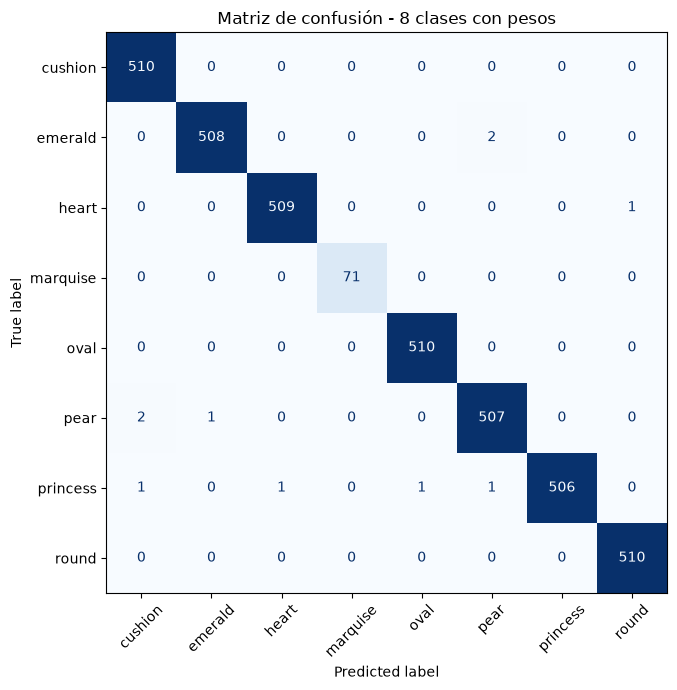

In [8]:
dibujar_matriz_confusion(y_real, y_pred_con_pesos, clases, '8 clases con pesos',
                         'graficas/matriz_marquise-con-pesos.png')

## Comparación de marquise con el resto de clases

In [9]:
informes = {
    'Sin pesos': classification_report(y_real, y_pred_sin_pesos, target_names=clases, output_dict=True),
    'Con pesos': classification_report(y_real, y_pred_con_pesos, target_names=clases, output_dict=True),
}
otras_clases = [clase for clase in clases if clase != 'marquise']

print(f'{"Modelo":10s} | {"Clase":16s} | {"Precision":9s} | {"Recall":6s} | {"F1":6s}')
for nombre, informe in informes.items():
    marquise = informe['marquise']
    precision_resto = np.mean([informe[clase]['precision'] for clase in otras_clases])
    recall_resto = np.mean([informe[clase]['recall'] for clase in otras_clases])
    f1_resto = np.mean([informe[clase]['f1-score'] for clase in otras_clases])
    print(f'{nombre:10s} | {"marquise":16s} | {marquise["precision"]:.4f}    | {marquise["recall"]:.4f} | {marquise["f1-score"]:.4f}')
    print(f'{nombre:10s} | {"media otras 7":16s} | {precision_resto:.4f}    | {recall_resto:.4f} | {f1_resto:.4f}')

Modelo     | Clase            | Precision | Recall | F1    
Sin pesos  | marquise         | 1.0000    | 0.9859 | 0.9929
Sin pesos  | media otras 7    | 0.9972    | 0.9975 | 0.9973
Con pesos  | marquise         | 1.0000    | 1.0000 | 1.0000
Con pesos  | media otras 7    | 0.9972    | 0.9972 | 0.9972
